# misPLA 6-plex analysis: CML patient (SP098) and healthy PBMC

Six protein-protein interactions were measured per cell by multiplexed in situ PLA
after treatment with five BCR-ABL1 tyrosine kinase inhibitors (TKIs), a BCL2 inhibitor,
and their combinations. Two replicate slides (A1, A2) per condition.

Input (both from the image analysis pipeline):
- `data/dots_per_cell_aggregated_all_tiles.csv.gz`: dots per cell, one row per cell and
  interaction, only cells with at least one dot
- `data/total_number_of_cells.csv`: number of segmented cells per tile, used to count
  the cells with zero dots

Every figure panel and table is written to the output folder. Run the cells from top to bottom.

## 0. Settings

In [45]:
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import false_discovery_control, mannwhitneyu, pearsonr, permutation_test
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

DOTS_FILE = Path("data/dots_per_cell_aggregated_all_tiles.csv.gz")
CELLS_FILE = Path("data/total_number_of_cells.csv")
OUT = Path("output")
OUT.mkdir(exist_ok=True)

PATIENTS = ["PBMC", "SP098"]          # healthy reference, CML patient
REFERENCE = "DMSO CTRL"               # vehicle, reference for all fold changes
CONTROLS = [REFERENCE]                # control samples, not shown as treatments
TKIS = ["Imatinib", "Dasatinib", "Nilotinib", "Bosutinib", "Ponatinib"]
COMBOS = ["Ima+BCL2", "Das+BCL2", "Nilo+BCL2", "Bosu+BCL2", "Pona+BCL2"]   # same order as TKIS
TREATMENTS = TKIS + COMBOS + ["BCL2"]
TREATMENT_SPELLING = {"Pon+BCL2": "Pona+BCL2"}   # typed in two ways in the file names
KEY_PPIS = ["JAK1-STAT3", "EGFR-GRB2"]   # the two interactions tested at single-cell level
SAMPLE = ["patient", "replication", "treatment", "ppi"]
ALPHA = 0.05                          # significance level after Benjamini-Hochberg
N_PERMUTATIONS = 10000
SEED = 0

# colours of the Nature Publishing Group palette (as in the R package ggsci)
PATIENT_COLOUR = {"PBMC": "#3C5488", "SP098": "#E64B35"}
PPI_COLOUR = {"JAK1-STAT3": "#4DBBD5", "EGFR-GRB2": "#F39B7F"}
GREY = "#8C8C8C"
REPLICATE_MARKER = {"A1": "o", "A2": "s"}
MM = 1 / 25.4                         # figure sizes below are given in mm

# journal figure style: Arial, 5-7 pt text, thin lines, text stays editable in the SVG
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 5, "axes.labelsize": 6, "axes.titlesize": 6,
    "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    "axes.linewidth": 0.5, "lines.linewidth": 0.75, "patch.linewidth": 0.4,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.handlelength": 1.2,
    "svg.fonttype": "none", "pdf.fonttype": 42,
    "figure.dpi": 200,                # only for the sharp display inside the notebook
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})


def save_panel(fig, name):
    """Save one panel as SVG (for Inkscape), PDF (vector) and 600 dpi PNG (quick look)."""
    fig.savefig(OUT / f"{name}.svg")
    fig.savefig(OUT / f"{name}.pdf")
    fig.savefig(OUT / f"{name}.png", dpi=600)
    print("saved", OUT / f"{name}.svg")

## 1. Load and clean the data

In [46]:
def clean(table):
    """The same clean-up for both input tables."""
    table = table.copy()
    # interaction name without barcode and dye: 'A_Cy5_JAK1-JAK3' -> 'JAK1-JAK3'
    table["ppi"] = table["name"].str.split("_", n=2).str[2]
    table["treatment"] = table["treatment"].replace(TREATMENT_SPELLING)
    # only DMSO and the drug treatments are analysed
    return table[table["treatment"].isin(TREATMENTS + CONTROLS)]


dots = clean(pd.read_csv(DOTS_FILE))                               # cells with >= 1 dot
segmented = clean(pd.read_csv(CELLS_FILE, skipinitialspace=True))  # all cells, counted per tile
print("positive cell rows:", len(dots), "  tiles used:", dots["tile_number"].nunique())

PPIS = sorted(dots["ppi"].unique())
print("interactions:", PPIS)
print(dots.groupby(["patient", "replication"])["treatment"].nunique())

# checkpoints: complete design, and the dots file only holds cells with at least 1 dot
assert sorted(dots["patient"].unique()) == PATIENTS
assert sorted(dots["treatment"].unique()) == sorted(TREATMENTS + CONTROLS)
assert len(PPIS) == 6
assert dots["dots_per_cell"].min() == 1

# checkpoint: in every tile the positive cells are found in, and not more than, the segmented cells
per_tile = dots.groupby(SAMPLE + ["tile_number"]).size().rename("positive_cells").to_frame()
per_tile = per_tile.join(segmented.set_index(SAMPLE + ["tile_number"])["nr_cells"])
assert per_tile["nr_cells"].notna().all()
assert (per_tile["positive_cells"] <= per_tile["nr_cells"]).all()

positive cell rows: 10189692   tiles used: 100
interactions: ['EGFR-GRB2', 'JAK1-JAK3', 'JAK1-PI3Kp85', 'JAK1-STAT3', 'JAK2-STAT5a', 'STAT3-STAT5a']
patient  replication
PBMC     A1             12
         A2             12
SP098    A1             12
         A2             12
Name: treatment, dtype: int64


## 2. Mean dots per cell for every sample, zero-dot cells included
One sample = one patient, replicate and treatment.
mean dots per cell = all dots of the sample / all segmented cells of the sample.

In [47]:
samples = dots.groupby(SAMPLE)["dots_per_cell"].agg(dots="sum", positive_cells="size")
samples["cells"] = segmented.groupby(SAMPLE)["nr_cells"].sum()
samples["mean_dots"] = samples["dots"] / samples["cells"]
samples["percent_positive"] = 100 * samples["positive_cells"] / samples["cells"]
samples = samples.reset_index()
# 2 patients x 2 replicates x 12 conditions x 6 interactions
assert len(samples) == 2 * 2 * 12 * 6
assert samples["cells"].notna().all()
samples.to_csv(OUT / "table_mean_dots_per_sample.csv", index=False)

print(samples.groupby("patient")["cells"].describe()[["min", "50%", "max"]].astype(int))
print("percent of cells with at least one dot:")
print(samples.groupby("patient")["percent_positive"].describe()[["min", "50%", "max"]].round(0))

# the same for both replicates together (used for the PCA, the per-patient heatmap and the tests)
pooled = samples.groupby(["patient", "treatment", "ppi"])[["dots", "cells"]].sum()
pooled["mean_dots"] = pooled["dots"] / pooled["cells"]

          min     50%     max
patient                      
PBMC     5581  117217  371884
SP098    3838    5956    7453
percent of cells with at least one dot:
          min   50%   max
patient                  
PBMC     12.0  32.0  99.0
SP098     8.0  30.0  92.0


## 3. Replicate reproducibility of the mean dots per cell
Panel: replicate A1 against A2. Each point is one condition and interaction.

PBMC Pearson r = 0.948  n points = 72
SP098 Pearson r = 0.945  n points = 72
saved output/panel_replicate_reproducibility.svg


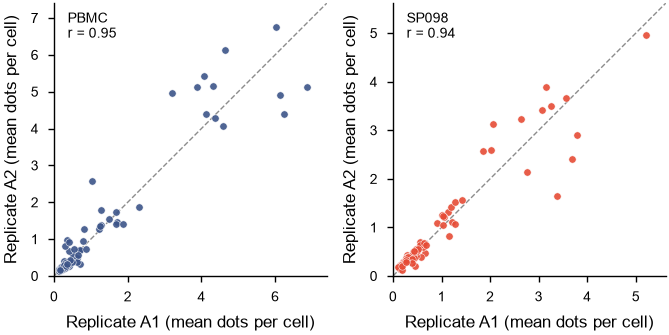

In [48]:
by_replicate = samples.pivot(index=["patient", "treatment", "ppi"],
                             columns="replication", values="mean_dots")
assert by_replicate.notna().all().all()

fig, axes = plt.subplots(1, 2, figsize=(88 * MM, 44 * MM))
for ax, patient in zip(axes, PATIENTS):
    one = by_replicate.loc[patient]
    r = pearsonr(one["A1"], one["A2"])[0]
    top = one.max().max() * 1.08
    ax.plot([0, top], [0, top], linestyle="--", color=GREY, linewidth=0.5, zorder=1)
    ax.scatter(one["A1"], one["A2"], s=7, color=PATIENT_COLOUR[patient],
               edgecolor="white", linewidth=0.2, alpha=0.9, zorder=2)
    ax.text(0.05, 0.97, f"{patient}\nr = {r:.2f}", transform=ax.transAxes, va="top")
    ax.set(xlim=(0, top), ylim=(0, top), aspect="equal",
           xlabel="Replicate A1 (mean dots per cell)",
           ylabel="Replicate A2 (mean dots per cell)")
    print(patient, "Pearson r =", round(r, 3), " n points =", len(one))
fig.tight_layout()
save_panel(fig, "panel_replicate_reproducibility")

## 4. Principal component analysis
One row per patient and condition (both replicates together), six interactions as columns.

In [49]:
def run_pca(table):
    """PCA of a samples x interactions table of mean dots per cell."""
    # log1p because dot counts are right-skewed; z-score so that every interaction weighs the same
    scaled = StandardScaler().fit_transform(np.log1p(table))
    pca = PCA().fit(scaled)
    explained = pca.explained_variance_ratio_ * 100
    scores = pd.DataFrame(pca.transform(scaled)[:, :2], columns=["PC1", "PC2"],
                          index=table.index).reset_index()
    # loadings scaled by the standard deviation of each component
    loadings = pd.DataFrame(pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2]),
                            columns=["PC1", "PC2"], index=table.columns)
    return scores, explained, loadings


pca_input = pooled["mean_dots"].unstack("ppi")
assert pca_input.shape == (24, 6)
scores, explained, loadings = run_pca(pca_input)

scores.to_csv(OUT / "table_pca_scores.csv", index=False)
loadings.to_csv(OUT / "table_pca_loadings.csv")
print("variance explained (%):", explained.round(1))
print(loadings.round(2))

variance explained (%): [52.1 33.4  5.8  3.9  2.7  2.1]
               PC1   PC2
ppi                     
EGFR-GRB2     0.92 -0.30
JAK1-JAK3     0.10  0.94
JAK1-PI3Kp85  0.91  0.09
JAK1-STAT3    0.88  0.31
JAK2-STAT5a   0.14  0.95
STAT3-STAT5a  0.88 -0.36


saved output/panel_pca_scree.svg


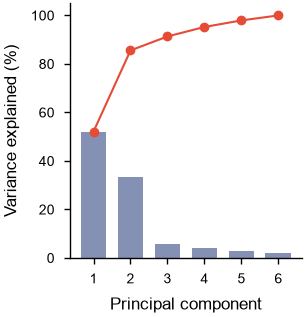

In [50]:
# Panel: scree plot (bars = each component, line = cumulative)
components = np.arange(1, len(explained) + 1)
fig, ax = plt.subplots(figsize=(38 * MM, 42 * MM))
ax.bar(components, explained, color="#8491B4", width=0.7)
ax.plot(components, np.cumsum(explained), marker="o", markersize=2.5, color="#E64B35")
ax.set(xlabel="Principal component", ylabel="Variance explained (%)",
       xticks=components, ylim=(0, 105))
save_panel(fig, "panel_pca_scree")

saved output/panel_pca_scores.svg


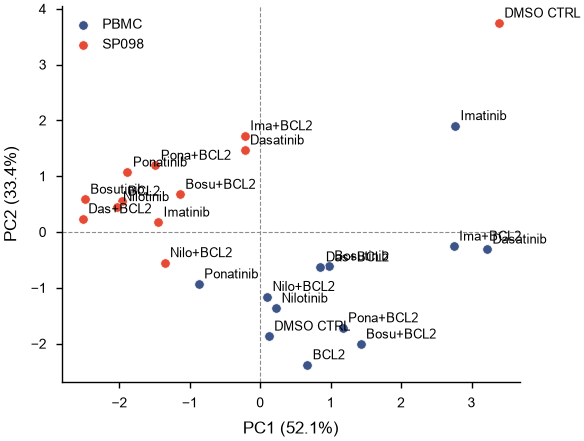

In [51]:
# Panel: PCA scores, colour = patient, each point labelled with its condition
fig, ax = plt.subplots(figsize=(75 * MM, 62 * MM))
ax.axhline(0, color=GREY, linewidth=0.4, linestyle="--", zorder=1)
ax.axvline(0, color=GREY, linewidth=0.4, linestyle="--", zorder=1)
for patient in PATIENTS:
    one = scores[scores["patient"] == patient]
    ax.scatter(one["PC1"], one["PC2"], s=12, color=PATIENT_COLOUR[patient],
               edgecolor="white", linewidth=0.3, label=patient, zorder=2)
for row in scores.itertuples():
    ax.annotate(row.treatment, (row.PC1, row.PC2), xytext=(2, 2),
                textcoords="offset points", fontsize=4.5)
ax.set(xlabel=f"PC1 ({explained[0]:.1f}%)", ylabel=f"PC2 ({explained[1]:.1f}%)")
ax.legend()
save_panel(fig, "panel_pca_scores")

saved output/panel_pca_loadings.svg


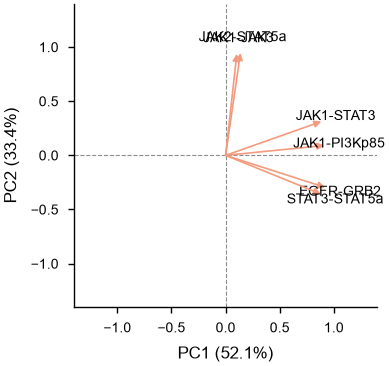

In [52]:
# Panel: PCA loadings, which interactions drive PC1 and PC2
ARROW_COLOUR = PPI_COLOUR["EGFR-GRB2"]
fig, ax = plt.subplots(figsize=(50 * MM, 50 * MM))
ax.axhline(0, color=GREY, linewidth=0.4, linestyle="--")
ax.axvline(0, color=GREY, linewidth=0.4, linestyle="--")
for ppi in PPIS:
    ax.annotate("", xy=loadings.loc[ppi], xytext=(0, 0),
                arrowprops={"arrowstyle": "-|>", "color": ARROW_COLOUR, "linewidth": 0.6,
                            "mutation_scale": 5, "shrinkA": 0, "shrinkB": 0})
    ax.text(loadings.loc[ppi, "PC1"] * 1.15, loadings.loc[ppi, "PC2"] * 1.15, ppi,
            ha="center", va="center", fontsize=5)
ax.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), aspect="equal",
       xlabel=f"PC1 ({explained[0]:.1f}%)", ylabel=f"PC2 ({explained[1]:.1f}%)")
save_panel(fig, "panel_pca_loadings")

### PCA within each patient, replicates shown separately (supplementary)
One PCA per patient. Each point is one replicate of one condition (12 conditions x 2 replicates),
circle = A1, square = A2, and a grey line joins the two replicates of the same condition.
Short lines mean the replicates agree.

PBMC variance explained (%): [59.2 15.6]
SP098 variance explained (%): [74.7  9.3]
saved output/panel_pca_replicates_per_patient.svg


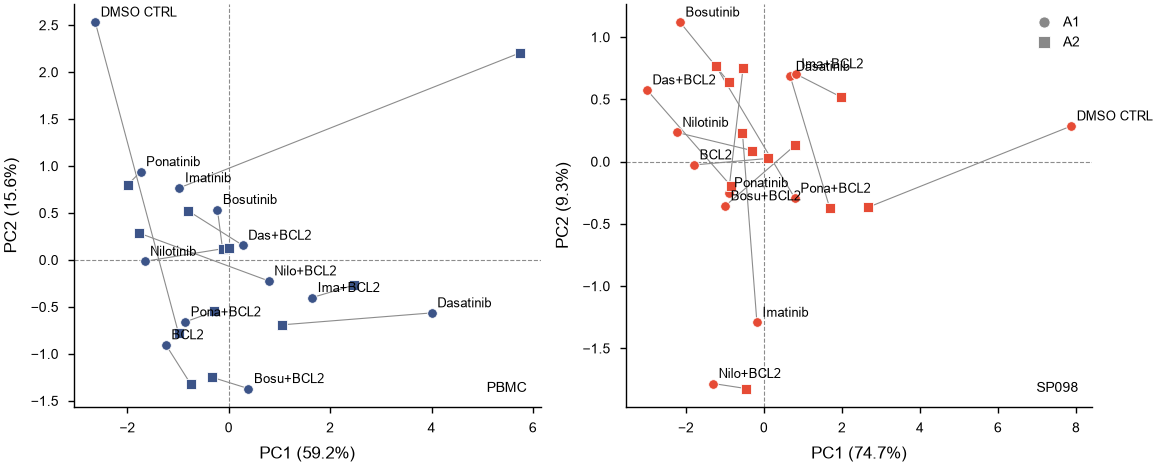

In [53]:
# Panel: one PCA per patient on the single replicates
fig, axes = plt.subplots(1, 2, figsize=(150 * MM, 62 * MM))
for ax, patient in zip(axes, PATIENTS):
    table = (samples[samples["patient"] == patient]
             .pivot(index=["treatment", "replication"], columns="ppi", values="mean_dots"))
    assert table.shape == (24, 6)
    rep_scores, rep_explained, rep_loadings = run_pca(table)
    rep_scores.insert(0, "patient", patient)
    rep_scores.to_csv(OUT / f"table_pca_replicates_{patient}.csv", index=False)
    print(patient, "variance explained (%):", rep_explained[:2].round(1))

    ax.axhline(0, color=GREY, linewidth=0.4, linestyle="--", zorder=1)
    ax.axvline(0, color=GREY, linewidth=0.4, linestyle="--", zorder=1)
    pairs = rep_scores.pivot(index="treatment", columns="replication", values=["PC1", "PC2"])
    for treatment, row in pairs.iterrows():
        ax.plot(row["PC1"], row["PC2"], color=GREY, linewidth=0.4, zorder=1)
    
    # Keep patient-specific colors for the actual scatter points on the plot
    for replicate, marker in REPLICATE_MARKER.items():
        one = rep_scores[rep_scores["replication"] == replicate]
        ax.scatter(one["PC1"], one["PC2"], s=12, marker=marker, color=PATIENT_COLOUR[patient],
                   edgecolor="white", linewidth=0.3, zorder=2)
                   
    for row in rep_scores[rep_scores["replication"] == "A1"].itertuples():
        ax.annotate(row.treatment, (row.PC1, row.PC2), xytext=(2, 2),
                    textcoords="offset points", fontsize=4.5)
    ax.text(0.97, 0.03, patient, transform=ax.transAxes, ha="right", va="bottom")
    ax.set(xlabel=f"PC1 ({rep_explained[0]:.1f}%)", ylabel=f"PC2 ({rep_explained[1]:.1f}%)")

# Create custom neutral black legend handles so they apply cleanly to both panels
legend_handles = [
    plt.Line2D([], [], color="#888888", marker=marker, linestyle="None",
                  markersize=4, label=replicate, markeredgecolor="white", markeredgewidth=0.3)
    for replicate, marker in REPLICATE_MARKER.items()
]
axes[1].legend(handles=legend_handles)

fig.tight_layout()
save_panel(fig, "panel_pca_replicates_per_patient")

## 5. Treatment effect per patient: log2 fold change against DMSO
Both replicates together. log2FC = log2((mean + 1) / (mean in DMSO + 1)).

In [55]:
effects_pooled = pooled["mean_dots"].reset_index()
dmso = (effects_pooled[effects_pooled["treatment"] == REFERENCE]
        .drop(columns="treatment").rename(columns={"mean_dots": "dmso_dots"}))

# every row gets the DMSO mean of the same patient and interaction
effects_pooled = effects_pooled.merge(dmso, on=["patient", "ppi"], validate="many_to_one")
assert len(effects_pooled) == len(pooled)
effects_pooled["log2fc"] = np.log2((effects_pooled["mean_dots"] + 1)
                                   / (effects_pooled["dmso_dots"] + 1))
# the control samples are not shown as treatments
effects_pooled = effects_pooled[~effects_pooled["treatment"].isin(CONTROLS)]
effects_pooled.to_csv(OUT / "table_log2fc_per_patient.csv", index=False)
pooled_log2fc = effects_pooled.set_index(["patient", "treatment", "ppi"])["log2fc"]
print(effects_pooled.groupby("patient")["log2fc"].describe().round(2))

         count  mean   std   min   25%   50%   75%   max
patient                                                 
PBMC      66.0  0.06  0.14 -0.30 -0.03  0.06  0.14  0.44
SP098     66.0 -0.38  0.23 -0.93 -0.52 -0.29 -0.20 -0.06


saved output/panel_log2fc_heatmap_per_patient.svg


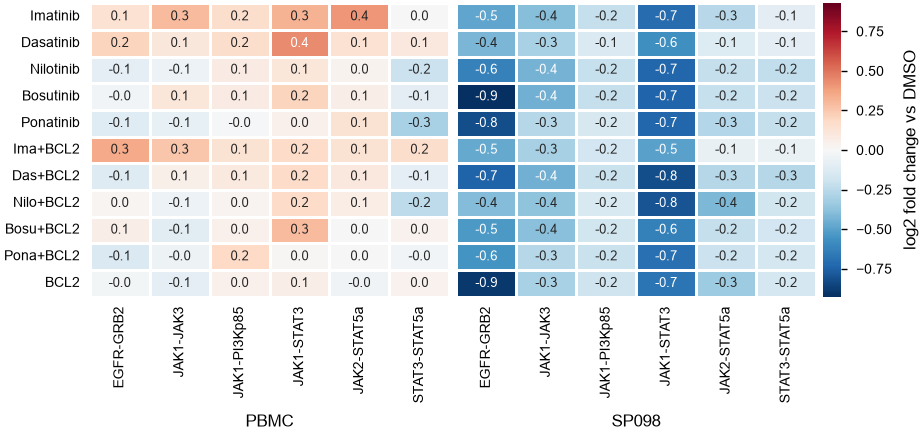

In [56]:
# Panel: heatmap of log2FC against DMSO, one block per patient, same colour scale
limit = effects_pooled["log2fc"].abs().max()
fig, axes = plt.subplots(1, 3, figsize=(120 * MM, 58 * MM),
                         gridspec_kw={"width_ratios": [1, 1, 0.05]})
for ax, patient in zip(axes, PATIENTS):
    matrix = pooled_log2fc[patient].unstack("ppi").loc[TREATMENTS]
    sns.heatmap(matrix, ax=ax, cmap="RdBu_r", vmin=-limit, vmax=limit,
                annot=True, fmt=".1f", annot_kws={"size": 4.5},
                linewidths=0.4, linecolor="white",
                cbar=(patient == "SP098"), cbar_ax=axes[2])
    ax.set(xlabel=patient, ylabel="")
    ax.tick_params(length=0)
axes[1].set_yticklabels([])
axes[2].set_ylabel("log2 fold change vs DMSO")
fig.tight_layout(w_pad=0.5)
save_panel(fig, "panel_log2fc_heatmap_per_patient")

## 6. Treatment effect in each replicate
Every replicate is compared with the DMSO mean of the same patient, both DMSO replicates together.
This shared reference keeps patient and replicate structure visible in the clustering.

In [57]:
# DMSO mean of each patient and interaction, both replicates together
dmso = (pooled["mean_dots"].reset_index()
        .query("treatment == @REFERENCE")
        .drop(columns="treatment")
        .rename(columns={"mean_dots": "dmso_dots"}))
effects = samples.merge(dmso, on=["patient", "ppi"], validate="many_to_one")
assert len(effects) == len(samples)
effects["log2fc"] = np.log2((effects["mean_dots"] + 1) / (effects["dmso_dots"] + 1))
effects = effects[~effects["treatment"].isin(CONTROLS)]
effects["sample"] = effects["patient"] + " " + effects["replication"] + " " + effects["treatment"]
effects.to_csv(OUT / "table_log2fc_per_replicate.csv", index=False)
print(effects.groupby(["patient", "replication"])["log2fc"].describe().round(2))

                     count  mean   std   min   25%   50%   75%   max
patient replication                                                 
PBMC    A1            66.0  0.06  0.17 -0.29 -0.04  0.04  0.16  0.57
        A2            66.0  0.08  0.19 -0.31 -0.02  0.07  0.14  0.68
SP098   A1            66.0 -0.41  0.26 -1.10 -0.55 -0.31 -0.21 -0.06
        A2            66.0 -0.35  0.23 -0.96 -0.49 -0.26 -0.17 -0.05


saved output/panel_log2fc_clustered_heatmap.svg


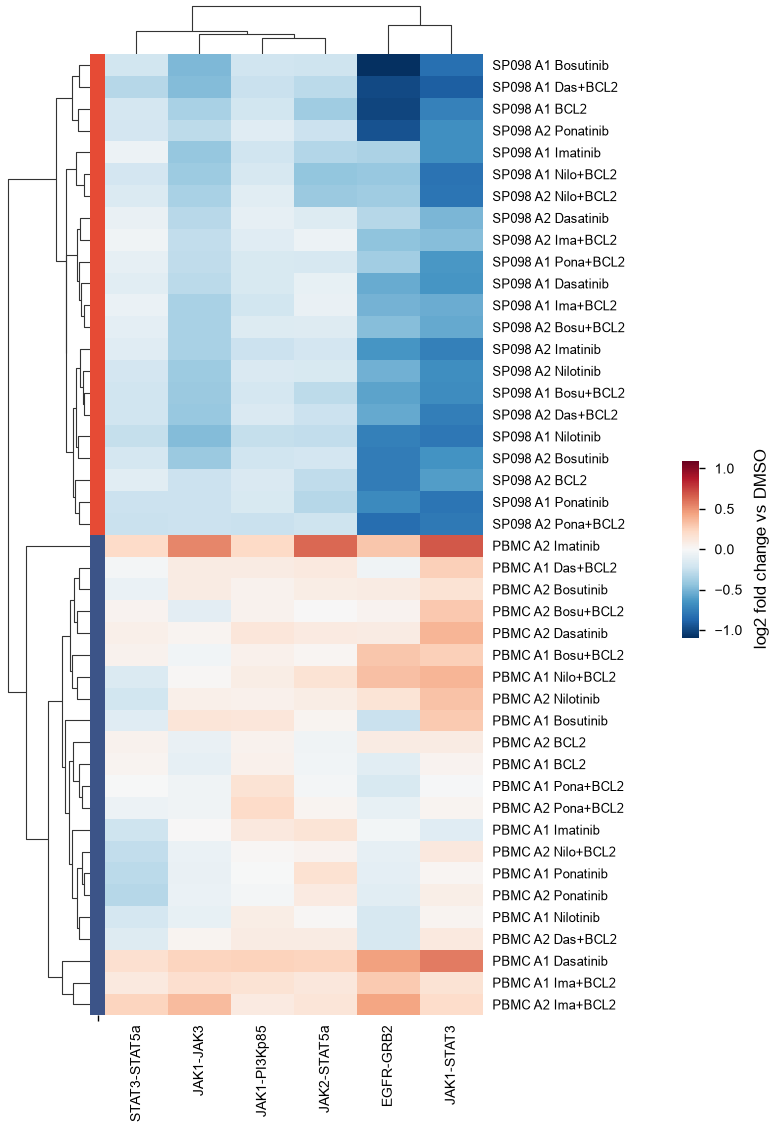

In [58]:
# Panel: clustered heatmap, rows = patient, replicate and treatment; side bar = patient
matrix = effects.pivot(index="sample", columns="ppi", values="log2fc")
assert matrix.shape == (2 * 2 * 11, 6)
patient_of_sample = effects.drop_duplicates("sample").set_index("sample")["patient"]
limit = np.abs(matrix.to_numpy()).max()

# hierarchical clustering: Euclidean distance, average linkage
grid = sns.clustermap(matrix, method="average", metric="euclidean",
                      cmap="RdBu_r", vmin=-limit, vmax=limit,
                      row_colors=patient_of_sample.loc[matrix.index].map(PATIENT_COLOUR).rename(""),
                      yticklabels=True, figsize=(88 * MM, 150 * MM),
                      dendrogram_ratio=(0.18, 0.05), colors_ratio=0.03,
                      tree_kws={"linewidths": 0.4},
                      cbar_pos=(1.0, 0.45, 0.025, 0.15),
                      cbar_kws={"label": "log2 fold change vs DMSO"})
grid.ax_heatmap.set(xlabel="", ylabel="")
grid.ax_heatmap.tick_params(axis="y", labelsize=4.5, length=0)
grid.ax_heatmap.tick_params(axis="x", length=0)
save_panel(grid.figure, "panel_log2fc_clustered_heatmap")

### Reproducibility of the treatment effects between replicates
Here each replicate is compared with its own DMSO (same patient and replicate).
The shared DMSO above cannot be used: both replicates would carry the same control noise,
which inflates their correlation.

In [59]:
# log2FC against the DMSO of the same patient and replicate (also used in sections 7 and 8)
own_dmso = (samples[samples["treatment"] == REFERENCE][["patient", "replication", "ppi", "mean_dots"]]
            .rename(columns={"mean_dots": "dmso_dots"}))
own = samples.merge(own_dmso, on=["patient", "replication", "ppi"], validate="many_to_one")
assert len(own) == len(samples)
own["log2fc"] = np.log2((own["mean_dots"] + 1) / (own["dmso_dots"] + 1))
own = own[~own["treatment"].isin(CONTROLS)]
rep_log2fc = own.pivot(index=["patient", "treatment", "ppi"], columns="replication", values="log2fc")
rep_log2fc.to_csv(OUT / "table_log2fc_per_replicate_own_dmso.csv")
print(rep_log2fc.loc["SP098"].loc[TKIS].unstack("ppi").swaplevel(axis=1)[KEY_PPIS].round(2))

ppi         JAK1-STAT3       EGFR-GRB2      
replication         A1    A2        A1    A2
treatment                                   
Imatinib         -0.98 -0.32     -0.37 -0.61
Dasatinib        -0.95 -0.07     -0.58 -0.29
Nilotinib        -1.09 -0.26     -0.77 -0.50
Bosutinib        -1.13 -0.23     -1.12 -0.74
Ponatinib        -1.11 -0.24     -0.72 -0.93


saved output/panel_effect_reproducibility_permutation.svg


,patient,n_pairs,pearson_r,permutation_p
0,PBMC,66,0.066878,0.584942
1,SP098,66,0.530232,0.000200


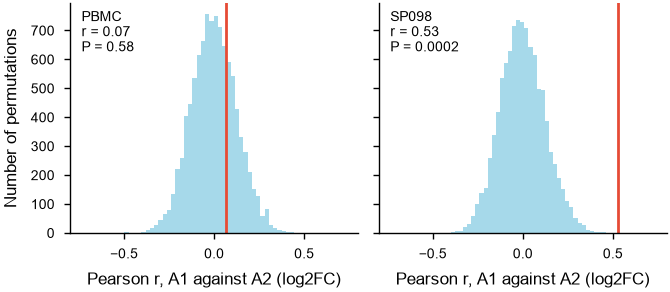

In [60]:
# Panel: is the agreement of the treatment effects between A1 and A2 better than chance?
# Permutation test: the A1/A2 pairing of the 66 effects (11 treatments x 6 interactions)
# is shuffled N_PERMUTATIONS times; blue = Pearson r of the shuffled pairs, red line = observed r.
def pearson_r(a1, a2):
    return pearsonr(a1, a2)[0]


rows = []
fig, axes = plt.subplots(1, 2, figsize=(88 * MM, 40 * MM), sharey=True)
for ax, patient in zip(axes, PATIENTS):
    one = rep_log2fc.loc[patient]
    test = permutation_test((one["A1"], one["A2"]), pearson_r, permutation_type="pairings",
                            n_resamples=N_PERMUTATIONS, alternative="two-sided",
                            random_state=SEED)
    rows.append({"patient": patient, "n_pairs": len(one),
                 "pearson_r": test.statistic, "permutation_p": test.pvalue})
    ax.hist(test.null_distribution, bins=40, color="#A6D9EA")
    ax.axvline(test.statistic, color="#E64B35", linewidth=1)
    ax.text(0.04, 0.97, f"{patient}\nr = {test.statistic:.2f}\nP = {test.pvalue:.2g}",
            transform=ax.transAxes, va="top")
    ax.set(xlabel="Pearson r, A1 against A2 (log2FC)", xlim=(-0.8, 0.8))
axes[0].set_ylabel("Number of permutations")
fig.tight_layout()
save_panel(fig, "panel_effect_reproducibility_permutation")

effect_reproducibility = pd.DataFrame(rows)
effect_reproducibility.to_csv(OUT / "table_effect_reproducibility.csv", index=False)
effect_reproducibility

## 7. Single-cell test in SP098: each TKI against DMSO
Two-sided Mann-Whitney U test on dots per cell of all cells (zero-dot cells included,
both replicates together), Benjamini-Hochberg correction over the 10 tests.
Effect size = rank-biserial correlation (-1 to +1, negative = fewer dots in treated cells).
Caveat: the cells come from two replicate slides, so the p-values overstate the evidence.
The log2FC of each replicate is therefore given in the table.

In [61]:
def dots_of_all_cells(patient, treatment, ppi):
    """Dots per cell of every cell of a condition: the positive cells plus the zero-dot cells."""
    positive = dots[(dots["patient"] == patient) & (dots["treatment"] == treatment)
                    & (dots["ppi"] == ppi)]["dots_per_cell"].to_numpy()
    n_cells = pooled.loc[(patient, treatment, ppi), "cells"]
    return np.concatenate([positive, np.zeros(n_cells - len(positive))])


def bar_panel(table, value, ylabel, name):
    """Bars = value of all cells (both replicates together), star = adjusted p < ALPHA."""
    x = np.arange(len(TKIS))
    width = 0.36
    fig, ax = plt.subplots(figsize=(70 * MM, 48 * MM))
    for i, ppi in enumerate(KEY_PPIS):
        one = table[table["ppi"] == ppi]
        position = x + (i - 0.5) * width
        ax.bar(position, one[value], width, color=PPI_COLOUR[ppi], edgecolor="black", label=ppi)
        for where in position[one["significant"].to_numpy()]:
            ax.text(where, 1.0, "*", ha="center", va="bottom", fontsize=7,
                    transform=ax.get_xaxis_transform())
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(TKIS, rotation=35, ha="right", rotation_mode="anchor")
    ax.set_ylabel(ylabel)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    save_panel(fig, name)

In [62]:
rows = []
for ppi in KEY_PPIS:
    dmso_cells = dots_of_all_cells("SP098", REFERENCE, ppi)
    for tki in TKIS:
        treated_cells = dots_of_all_cells("SP098", tki, ppi)
        u, p = mannwhitneyu(treated_cells, dmso_cells, alternative="two-sided")
        rows.append({
            "ppi": ppi, "treatment": tki,
            "n_treated": len(treated_cells), "n_dmso": len(dmso_cells),
            "log2fc": pooled_log2fc["SP098", tki, ppi],
            "log2fc_A1": rep_log2fc.loc[("SP098", tki, ppi), "A1"],
            "log2fc_A2": rep_log2fc.loc[("SP098", tki, ppi), "A2"],
            "effect_r": 2 * u / (len(treated_cells) * len(dmso_cells)) - 1,
            "p": p,
        })
tki_test = pd.DataFrame(rows)
tki_test["p_adj"] = false_discovery_control(tki_test["p"], method="bh")
tki_test["significant"] = tki_test["p_adj"] < ALPHA
assert len(tki_test) == len(KEY_PPIS) * len(TKIS)
tki_test.to_csv(OUT / "table_tki_vs_dmso_SP098.csv", index=False)
tki_test.round(3)

,ppi,treatment,n_treated,n_dmso,log2fc,log2fc_A1,log2fc_A2,effect_r,p,p_adj,significant
0,JAK1-STAT3,Imatinib,11788,14254,-0.711,-0.978,-0.321,-0.319,0.0,0.0,True
1,JAK1-STAT3,Dasatinib,10969,14254,-0.565,-0.946,-0.070,-0.245,0.0,0.0,True
2,JAK1-STAT3,Nilotinib,11522,14254,-0.733,-1.093,-0.256,-0.328,0.0,0.0,True
3,JAK1-STAT3,Bosutinib,12398,14254,-0.741,-1.132,-0.226,-0.335,0.0,0.0,True
4,JAK1-STAT3,Ponatinib,13835,14254,-0.736,-1.108,-0.244,-0.332,0.0,0.0,True
5,EGFR-GRB2,Imatinib,11788,14254,-0.488,-0.371,-0.615,-0.295,0.0,0.0,True
6,EGFR-GRB2,Dasatinib,10969,14254,-0.423,-0.578,-0.287,-0.253,0.0,0.0,True
7,EGFR-GRB2,Nilotinib,11522,14254,-0.627,-0.771,-0.496,-0.350,0.0,0.0,True
8,EGFR-GRB2,Bosutinib,12398,14254,-0.927,-1.122,-0.738,-0.490,0.0,0.0,True
9,EGFR-GRB2,Ponatinib,13835,14254,-0.822,-0.720,-0.930,-0.446,0.0,0.0,True


saved output/panel_tki_vs_dmso_SP098.svg


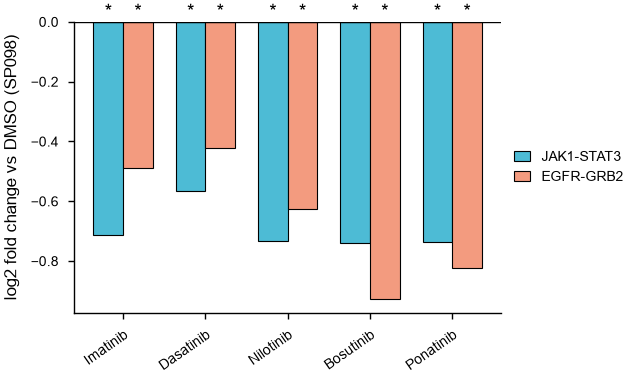

In [63]:
# Panel: log2FC against DMSO for each TKI in SP098
bar_panel(tki_test, "log2fc", "log2 fold change vs DMSO (SP098)", "panel_tki_vs_dmso_SP098")

## 8. Does adding the BCL2 inhibitor change the TKI effect in SP098?
delta = log2FC(TKI + BCL2 inhibitor) - log2FC(TKI alone); near 0 = no added change.
Same Mann-Whitney test and correction as above, combination against TKI alone.

In [64]:
rows = []
for ppi in KEY_PPIS:
    for tki, combo in zip(TKIS, COMBOS):
        tki_cells = dots_of_all_cells("SP098", tki, ppi)
        combo_cells = dots_of_all_cells("SP098", combo, ppi)
        u, p = mannwhitneyu(combo_cells, tki_cells, alternative="two-sided")
        combo_minus_tki = rep_log2fc.loc[("SP098", combo, ppi)] - rep_log2fc.loc[("SP098", tki, ppi)]
        rows.append({
            "ppi": ppi, "tki": tki, "combination": combo,
            "delta": pooled_log2fc["SP098", combo, ppi] - pooled_log2fc["SP098", tki, ppi],
            "delta_A1": combo_minus_tki["A1"], "delta_A2": combo_minus_tki["A2"],
            "effect_r": 2 * u / (len(combo_cells) * len(tki_cells)) - 1,
            "p": p,
        })
combo_test = pd.DataFrame(rows)
combo_test["p_adj"] = false_discovery_control(combo_test["p"], method="bh")
combo_test["significant"] = combo_test["p_adj"] < ALPHA
combo_test.to_csv(OUT / "table_bcl2_combination_SP098.csv", index=False)
print("delta range:", combo_test["delta"].min().round(2), "to", combo_test["delta"].max().round(2),
      " mean:", combo_test["delta"].mean().round(2))
combo_test.round(3)

delta range: -0.32 to 0.4  mean: 0.06


,ppi,tki,combination,delta,delta_A1,delta_A2,effect_r,p,p_adj,significant
0,JAK1-STAT3,Imatinib,Ima+BCL2,0.206,0.127,0.279,0.106,0.000,0.000,True
1,JAK1-STAT3,Dasatinib,Das+BCL2,-0.260,-0.260,-0.264,-0.145,0.000,0.000,True
2,JAK1-STAT3,Nilotinib,Nilo+BCL2,-0.069,-0.018,-0.115,-0.045,0.000,0.000,True
3,JAK1-STAT3,Bosutinib,Bosu+BCL2,0.109,0.137,0.095,0.061,0.000,0.000,True
4,JAK1-STAT3,Ponatinib,Pona+BCL2,0.039,0.168,-0.112,0.027,0.000,0.000,True
5,EGFR-GRB2,Imatinib,Ima+BCL2,0.015,-0.169,0.206,0.014,0.063,0.063,False
6,EGFR-GRB2,Dasatinib,Das+BCL2,-0.323,-0.440,-0.248,-0.166,0.000,0.000,True
7,EGFR-GRB2,Nilotinib,Nilo+BCL2,0.226,0.328,0.137,0.122,0.000,0.000,True
8,EGFR-GRB2,Bosutinib,Bosu+BCL2,0.397,0.512,0.303,0.204,0.000,0.000,True
9,EGFR-GRB2,Ponatinib,Pona+BCL2,0.268,0.315,0.125,0.148,0.000,0.000,True


saved output/panel_bcl2_combination_SP098.svg


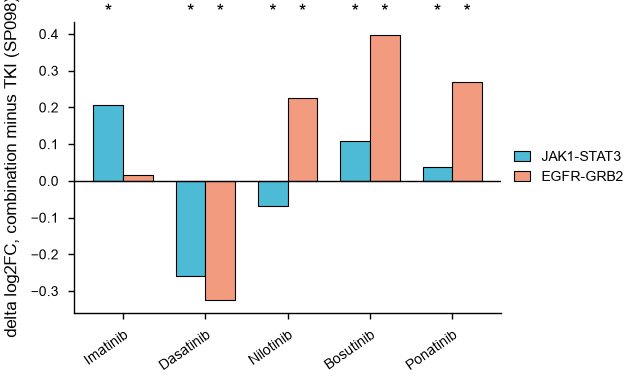

In [65]:
# Panel: delta log2FC, combination minus TKI alone, in SP098
bar_panel(combo_test, "delta", "delta log2FC, combination minus TKI (SP098)",
          "panel_bcl2_combination_SP098")

9. Extra charts to visualize the single cell view of the data

9-1. interactions in the same cell

9-2. single-cell distributions (ECDF)

In [66]:
# Dots per cell of every single cell: one interaction, DMSO against one TKI, each replicate and patient
SHOW_PPI = "EGFR-GRB2"
SHOW_TKI = "Bosutinib"
TREATMENT_COLOUR = {REFERENCE: GREY, SHOW_TKI: "#E64B35"}
REPLICATE_LINE = {"A1": "-", "A2": "--"}

cells_in_sample = samples.set_index(SAMPLE)["cells"]
groups = []
for patient in PATIENTS:
    for treatment in [REFERENCE, SHOW_TKI]:
        for replicate in ["A1", "A2"]:
            positive = dots[(dots["patient"] == patient) & (dots["replication"] == replicate)
                            & (dots["treatment"] == treatment)
                            & (dots["ppi"] == SHOW_PPI)]["dots_per_cell"]
            n_cells = int(cells_in_sample[patient, replicate, treatment, SHOW_PPI])
            # the zero-dot cells are added to the cells with dots
            values = np.concatenate([positive, np.zeros(n_cells - len(positive))])
            groups.append(pd.DataFrame({"patient": patient, "treatment": treatment,
                                        "replication": replicate, "dots_per_cell": values}))
shown = pd.concat(groups, ignore_index=True)
print(shown.groupby(["patient", "treatment", "replication"], sort=False)["dots_per_cell"]
      .agg(["size", "mean", "median"]).round(2))
top = shown["dots_per_cell"].quantile(0.99)   # axis limit, the highest 1% of cells is cut off

                                 size  mean  median
patient treatment replication                      
PBMC    DMSO CTRL A1            12902  3.20     3.0
                  A2           100564  4.97     5.0
        Bosutinib A1             5581  3.87     2.0
                  A2             8910  5.12     5.0
SP098   DMSO CTRL A1             7453  5.20     4.0
                  A2             6801  4.97     4.0
        Bosutinib A1             6382  1.85     1.0
                  A2             6016  2.58     2.0


saved output/panel_single_cell_ecdf.svg


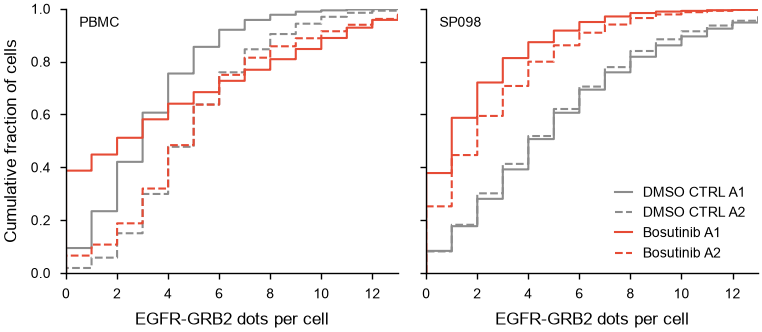

In [67]:
# Panel: empirical cumulative distribution per patient, colour = treatment, line style = replicate
fig, axes = plt.subplots(1, 2, figsize=(100 * MM, 45 * MM), sharey=True)
for ax, patient in zip(axes, PATIENTS):
    one_patient = shown[shown["patient"] == patient]
    for (treatment, replicate), one in one_patient.groupby(["treatment", "replication"], sort=False):
        ax.ecdf(one["dots_per_cell"], color=TREATMENT_COLOUR[treatment],
                linestyle=REPLICATE_LINE[replicate], label=f"{treatment} {replicate}")
    ax.text(0.04, 0.97, patient, transform=ax.transAxes, va="top")
    ax.set(xlim=(0, top), xlabel=f"{SHOW_PPI} dots per cell")
axes[0].set_ylabel("Cumulative fraction of cells")
axes[1].legend(loc="lower right")
fig.tight_layout()
save_panel(fig, "panel_single_cell_ecdf")

saved output/panel_single_cell_ecdf_all_tkis_JAK1-STAT3.svg
saved output/panel_single_cell_ecdf_all_tkis_EGFR-GRB2.svg


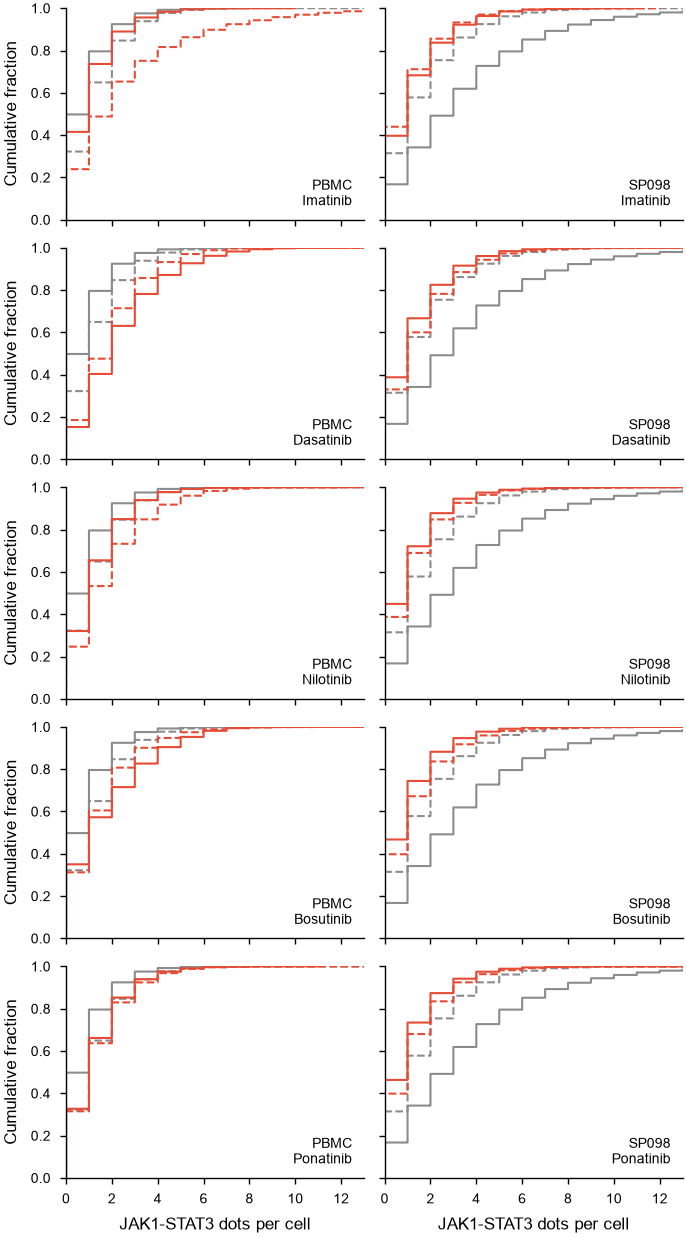

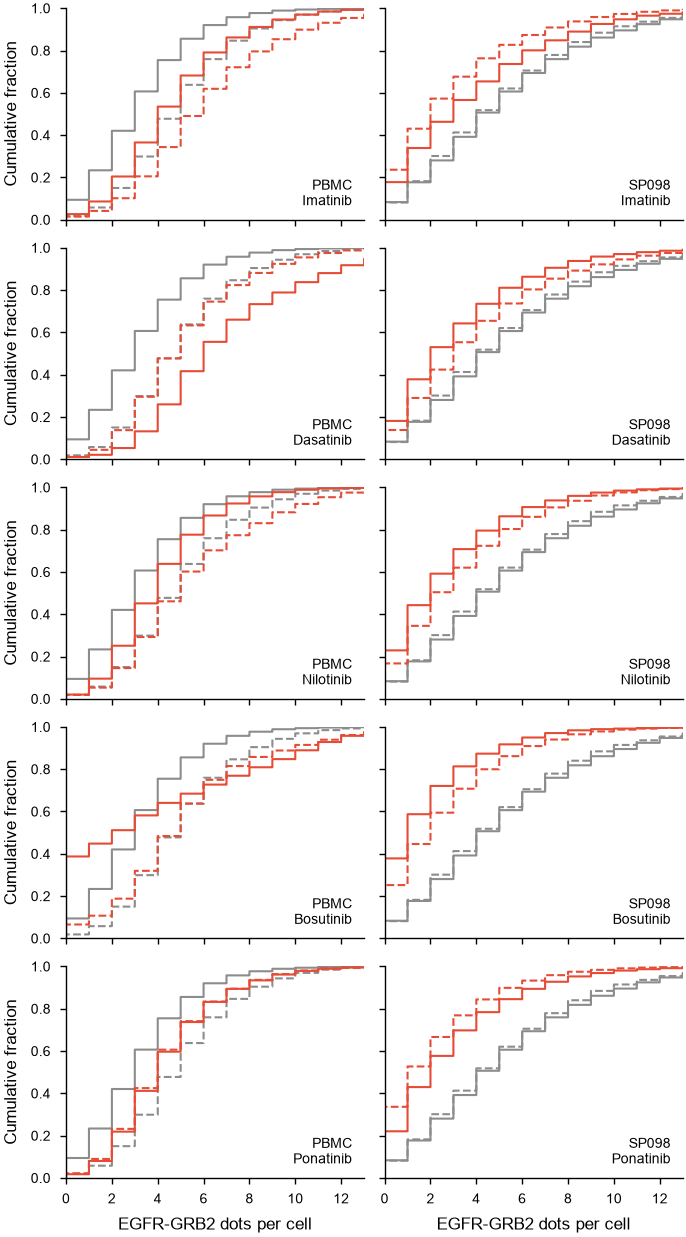

In [68]:
# Supplementary panel: ECDF of every TKI against DMSO, one figure per key interaction
# rows = TKIs, columns = patients; colour = treatment, line style = replicate
def cells_of(patient, replicate, treatment, ppi):
    """Dots per cell of all cells of one sample, zero-dot cells included."""
    positive = dots[(dots["patient"] == patient) & (dots["replication"] == replicate)
                    & (dots["treatment"] == treatment) & (dots["ppi"] == ppi)]["dots_per_cell"]
    n_cells = int(cells_in_sample[patient, replicate, treatment, ppi])
    return np.concatenate([positive, np.zeros(n_cells - len(positive))])


for ppi in KEY_PPIS:
    fig, axes = plt.subplots(len(TKIS), 2, figsize=(90 * MM, 160 * MM), sharex=True, sharey=True)
    for row, tki in enumerate(TKIS):
        for col, patient in enumerate(PATIENTS):
            ax = axes[row, col]
            for treatment, colour in [(REFERENCE, GREY), (tki, "#E64B35")]:
                for replicate, line in REPLICATE_LINE.items():
                    ax.ecdf(cells_of(patient, replicate, treatment, ppi), color=colour,
                            linestyle=line, label=f"{treatment} {replicate}")
            ax.text(0.96, 0.05, f"{patient}\n{tki}", transform=ax.transAxes, ha="right", va="bottom")
        axes[row, 0].set_ylabel("Cumulative fraction")
    for col in range(2):
        axes[-1, col].set(xlim=(0, top), xlabel=f"{ppi} dots per cell")
    fig.tight_layout()
    save_panel(fig, f"panel_single_cell_ecdf_all_tkis_{ppi}")

9-3. fewer positive cells, or fewer dots per positive cell?

saved output/panel_positive_cells_and_dots.svg


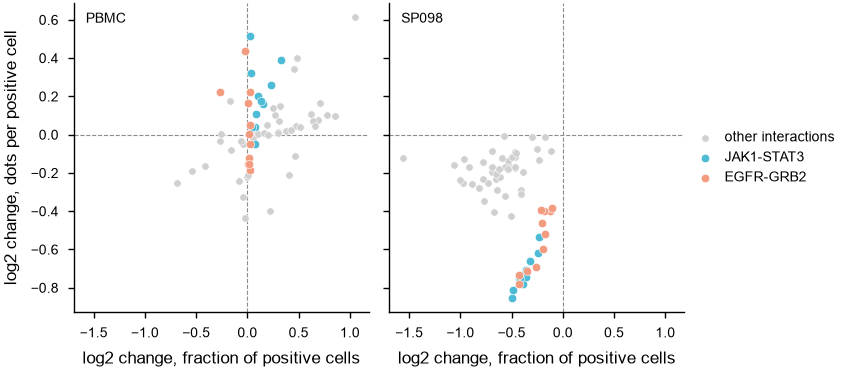

In [69]:
# mean dots per cell = fraction of positive cells x dots per positive cell.
# Both parts are compared with DMSO, so their two log2 changes add up to the change of the mean.
readouts = ["fraction_positive", "dots_per_positive_cell"]
parts = samples.groupby(["patient", "treatment", "ppi"])[["dots", "positive_cells", "cells"]].sum()
parts["fraction_positive"] = parts["positive_cells"] / parts["cells"]
parts["dots_per_positive_cell"] = parts["dots"] / parts["positive_cells"]
parts = parts.reset_index()

dmso_parts = (parts[parts["treatment"] == REFERENCE][["patient", "ppi"] + readouts]
              .rename(columns={name: f"dmso_{name}" for name in readouts}))
parts = parts.merge(dmso_parts, on=["patient", "ppi"], validate="many_to_one")
# no pseudocount: both readouts are above 0 in every sample
for name in readouts:
    parts[f"log2_{name}"] = np.log2(parts[name] / parts[f"dmso_{name}"])
parts = parts[~parts["treatment"].isin(CONTROLS)]
assert len(parts) == 2 * 11 * 6
parts.to_csv(OUT / "table_positive_cells_and_dots.csv", index=False)

# Panel: each point = one treatment and interaction; left = fewer positive cells,
# down = fewer dots per positive cell
other_ppis = [ppi for ppi in PPIS if ppi not in KEY_PPIS]
fig, axes = plt.subplots(1, 2, figsize=(110 * MM, 50 * MM), sharex=True, sharey=True)
for ax, patient in zip(axes, PATIENTS):
    one = parts[parts["patient"] == patient]
    ax.axhline(0, color=GREY, linewidth=0.4, linestyle="--", zorder=1)
    ax.axvline(0, color=GREY, linewidth=0.4, linestyle="--", zorder=1)
    rest = one[one["ppi"].isin(other_ppis)]
    ax.scatter(rest["log2_fraction_positive"], rest["log2_dots_per_positive_cell"], s=7,
               color="#D0D0D0", edgecolor="white", linewidth=0.2, label="other interactions")
    for ppi in KEY_PPIS:
        key = one[one["ppi"] == ppi]
        ax.scatter(key["log2_fraction_positive"], key["log2_dots_per_positive_cell"], s=9,
                   color=PPI_COLOUR[ppi], edgecolor="white", linewidth=0.2, label=ppi, zorder=3)
    ax.text(0.04, 0.97, patient, transform=ax.transAxes, va="top")
    ax.set_xlabel("log2 change, fraction of positive cells")
axes[0].set_ylabel("log2 change, dots per positive cell")
axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
save_panel(fig, "panel_positive_cells_and_dots")

saved output/panel_mean_split_per_patient.svg


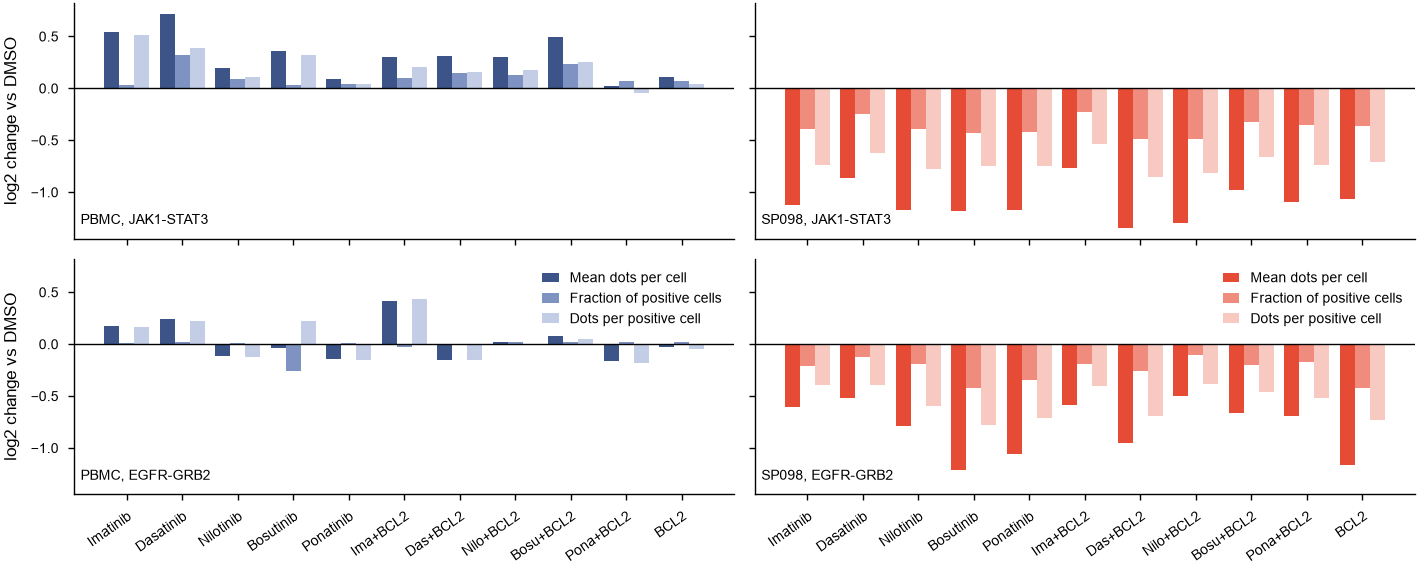

In [70]:
# Panel: the change in mean dots per cell split into its two parts, PBMC (left) and SP098 (right)
# log2(mean / DMSO mean) = log2 change of fraction positive + log2 change of dots per positive cell
parts["log2_mean"] = parts["log2_fraction_positive"] + parts["log2_dots_per_positive_cell"]
BARS = {"log2_mean": "Mean dots per cell",
        "log2_fraction_positive": "Fraction of positive cells",
        "log2_dots_per_positive_cell": "Dots per positive cell"}
# dark = total, lighter = its two parts
SHADES = {"PBMC": ["#3C5488", "#7F93C2", "#C3CDE6"],
          "SP098": ["#E64B35", "#F08C7D", "#F8C9C1"]}

x = np.arange(len(TREATMENTS))
width = 0.27
fig, axes = plt.subplots(2, 2, figsize=(183 * MM, 75 * MM), sharex=True, sharey=True)
for col, patient in enumerate(PATIENTS):
    for row, ppi in enumerate(KEY_PPIS):
        ax = axes[row, col]
        one = (parts[(parts["patient"] == patient) & (parts["ppi"] == ppi)]
               .set_index("treatment").loc[TREATMENTS])
        for i, (column, label) in enumerate(BARS.items()):
            ax.bar(x + (i - 1) * width, one[column], width, color=SHADES[patient][i], label=label)
        ax.axhline(0, color="black", linewidth=0.5)
        ax.text(0.01, 0.05, f"{patient}, {ppi}", transform=ax.transAxes, va="bottom")
    axes[1, col].legend(loc="upper right")
    axes[1, col].set_xticks(x)
    axes[1, col].set_xticklabels(TREATMENTS, rotation=35, ha="right", rotation_mode="anchor")
for row in range(2):
    axes[row, 0].set_ylabel("log2 change vs DMSO")
fig.tight_layout()
save_panel(fig, "panel_mean_split_per_patient")